In [1]:
import json
import pandas as pd
import matplotlib.pyplot as plt
import lhapdf
import pineappl
from pineappl.convolutions import Conv, ConvType

In [2]:
# table 7 in https://arxiv.org/pdf/1506.06042
with open("HERA_xF3.json") as f:
    hera_data = json.load(f)

In [3]:
data = {"x": [], "Q2": [], "exp_cv": [], "exp_error": []}
for dat in hera_data["values"]:
    Q2 = dat["x"][0]["value"]
    x = dat["x"][1]["value"]
    xF3 = dat["y"][0]["value"]
    error = 0
    for error_type in dat["y"][0]["errors"]:
        error += float(error_type["symerror"]) ** 2
    error = error ** 0.5
    data["exp_error"].append(error)
    data["Q2"].append(float(Q2))
    data["x"].append(float(x))
    data["exp_cv"].append(float(xF3))
data = pd.DataFrame(data)

In [4]:
pdfset = "NNPDF40_nnlo_as_01180"
pdf = lhapdf.mkPDF(pdfset, 0)
conv_type = ConvType(polarized=False, time_like=False)
conv_object = Conv(convolution_types=conv_type, pid=2212)
grid = pineappl.grid.Grid.read("HERA_F3.pineappl.lz4")
prediction = grid.convolve(
    pdg_convs=[conv_object],  # Similar convolutions for symmetric protons
    xfxs=[pdf.xfxQ2],  # Similar PDF sets for symmetric protons
    alphas=pdf.alphasQ2,
)

mZ = 91.1876
sth2 = 0.23127
cth2 = 1 - sth2
kZ = data["Q2"]/((data["Q2"] + mZ ** 2) * 4 * cth2 * sth2)
prefactor = 2 / kZ
data["theory"] = prediction * prefactor
data.to_csv("HERA_xF3.csv", index=True)

LHAPDF 6.5.5 loading /Users/jaco/miniconda3/envs/nnpdf_dev/share/LHAPDF/NNPDF40_nnlo_as_01180/NNPDF40_nnlo_as_01180_0000.dat
NNPDF40_nnlo_as_01180 PDF set, member #0, version 1; LHAPDF ID = 331100


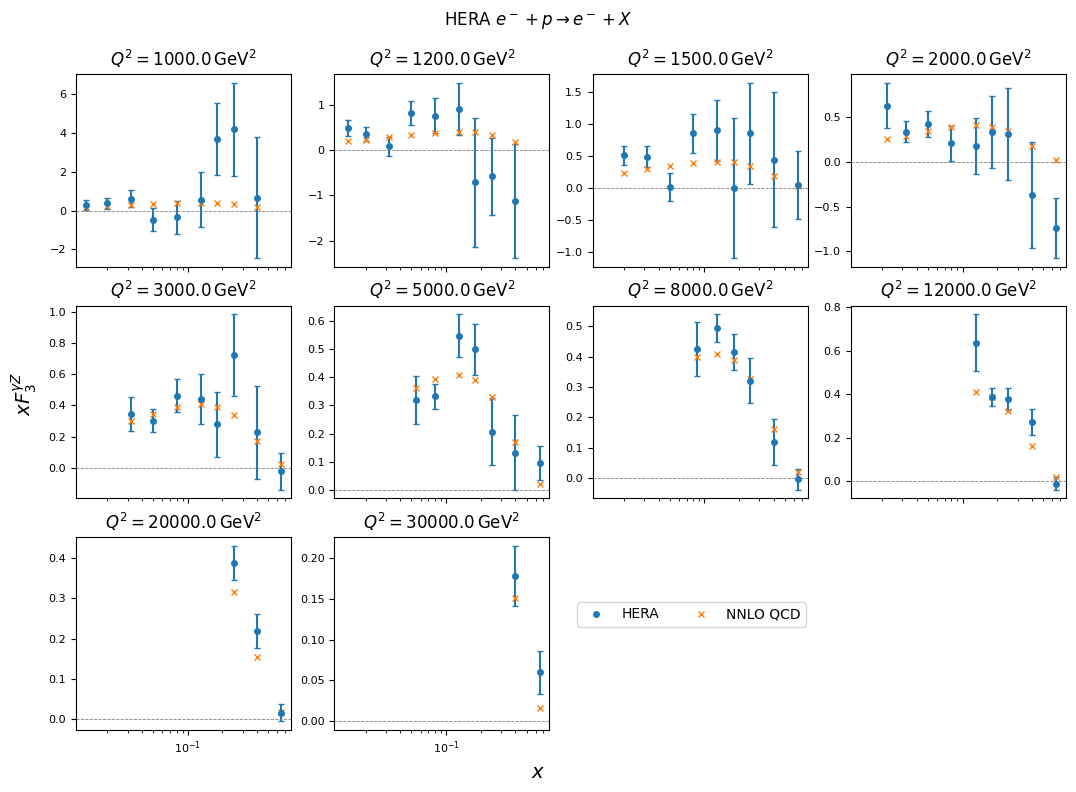

In [8]:
import numpy as np
import matplotlib.ticker as mticker

q2_values = np.sort(data["Q2"].unique())
n_used = len(q2_values)

fig, axes = plt.subplots(
    3, 4,
    figsize=(11, 8),
    sharex=True,
    sharey=False
)

fig.suptitle(r"HERA $e^- + p \to e^- + X$")

# Make panels touch
fig.subplots_adjust(
    left=0.08,
    right=0.98,
    bottom=0.08,
    top=0.9,
    wspace=0.2,
    hspace=0.2
)

axes_flat = axes.flatten()

exp_handle = None
th_handle = None

for i, (q2, ax) in enumerate(zip(q2_values, axes_flat)):
    dat = data[data["Q2"] == q2]

    # Plot data
    eb = ax.errorbar(
        dat["x"], dat["exp_cv"],
        yerr=dat["exp_error"],
        fmt="o", capsize=2, ms=4
    )
    if exp_handle is None:
        exp_handle = eb[0]

    (pth,) = ax.plot(dat["x"], dat["theory"], "x", ms=5)
    if th_handle is None:
        th_handle = pth

    # Log axis
    ax.set_xscale("log")
    ax.xaxis.set_major_locator(mticker.LogLocator(base=10))
    ax.xaxis.set_minor_formatter(mticker.NullFormatter())

    # Zero line
    ax.axhline(0, color="gray", linestyle="--", linewidth=0.6)

    ax.set_title(f"$Q^2 = {q2} \\, \\mathrm{{GeV}}^2$")

    # Tick formatting
    ax.tick_params(axis="both", labelsize=8)

# Remove unused axes
for ax in axes_flat[n_used:]:
    fig.delaxes(ax)


# Global axis labels
fig.text(0.5, 0.02, r"$x$", ha="center", fontsize=14)
fig.text(0.02, 0.5, r"$xF_3^{\gamma Z}$", va="center",
         rotation="vertical", fontsize=14)

# Legend
fig.legend(
    handles=[exp_handle, th_handle],
    labels=["HERA", "NNLO QCD"],
    loc="lower right",
    ncols=2,
    frameon=True,
    bbox_to_anchor=(0.75, 0.2),
)

fig.savefig("HERA_xF3.pdf")



In [9]:
# compute the chi2
chi2 = np.sum(((data["theory"] - data["exp_cv"]) / data["exp_error"]) ** 2)
print(f"Chi2: {chi2:.2f} / {len(data)} = {chi2/len(data):.2f}")

Chi2: 77.90 / 67 = 1.16
